In [1]:
import re
import os
import time
import warnings

import torch
import torchvision.transforms.functional as F
import matplotlib.pyplot as plt

from torch.export import export
from torchvision.io import decode_image

from executorch import version
from executorch.runtime import Runtime
from executorch.exir import to_edge_transform_and_lower
from executorch.backends.xnnpack.partition.xnnpack_partitioner import XnnpackPartitioner

from transformer_net import TransformerNet


warnings.simplefilter("ignore", FutureWarning)
print("Executorch version: ", version.__version__)

Skipping import of cpp extensions due to incompatible torch version 2.10.0 for torchao version 0.15.0             Please see https://github.com/pytorch/ao/issues/2919 for more info
W0306 16:17:33.409000 58236 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Executorch version:  1.1.0


In [2]:
# NOTE: Use `download_saved_models.py` to download the pre-trained models before
# running this export script.
STYLES_MODELS = {
    "candy": "saved_models/candy.pth",
    "mosaic": "saved_models/mosaic.pth",
    "udnie": "saved_models/udnie.pth",
    "rain_princess": "saved_models/rain_princess.pth",
}

SUFFIX = "_xnnpack_fp32"
EXPORT_DIR = "exports"
MODEL_PATH: dict[str, str] = {}

# NOTE: The original code does not resize the input image, since the network is
# fully convolutional and can handle arbitrary input sizes. However, for the
# exported model, we need to resize the input to a fixed size. The particular
# size of 640x640 is chosen to be large enough to preserve details while being
# small enough for efficient inference. This size was also used in the original
# export.
RESIZE_SIZE = [640, 640]


# Based on the implementation of `stylize()` function from:
# https://github.com/pytorch/examples/blob/main/fast_neural_style/neural_style/neural_style.py
def load_style_transfer_model(wts_path: str) -> torch.nn.Module:
    state_dict = torch.load(wts_path)
    for k in list(state_dict.keys()):
        if re.search(r"in\d+\.running_(mean|var)$", k):
            del state_dict[k]

    model = TransformerNet()
    model.load_state_dict(state_dict)
    model.eval()
    return model

In [3]:
print("Exporting models...")

for model_name, wts_path in STYLES_MODELS.items():
    model = load_style_transfer_model(wts_path)
    inputs = (torch.randn(1, 3, *RESIZE_SIZE),)

    program = to_edge_transform_and_lower(export(model, inputs), partitioner=[XnnpackPartitioner()])
    program = program.to_executorch()

    with open(path := f"{EXPORT_DIR}/style_transfer_{model_name}{SUFFIX}.pte", "wb") as f:
        MODEL_PATH[model_name] = path
        f.write(program.buffer)

    print(f"Exported {path}\n")

Exporting models...
Exported exports/style_transfer_candy_xnnpack_fp32.pte

Exported exports/style_transfer_mosaic_xnnpack_fp32.pte

Exported exports/style_transfer_udnie_xnnpack_fp32.pte

Exported exports/style_transfer_rain_princess_xnnpack_fp32.pte



[program.cpp:154] InternalConsistency verification requested but not available
[cpuinfo_utils.cpp:71] Reading file /sys/devices/soc0/image_version
[cpuinfo_utils.cpp:87] Failed to open midr file /sys/devices/soc0/image_version
[cpuinfo_utils.cpp:167] Number of efficient cores 4


Verifying models...
CANDY
Model size: 6.50 MB
Run successfully via Executorch in 1.14 seconds

Comparisson passed!



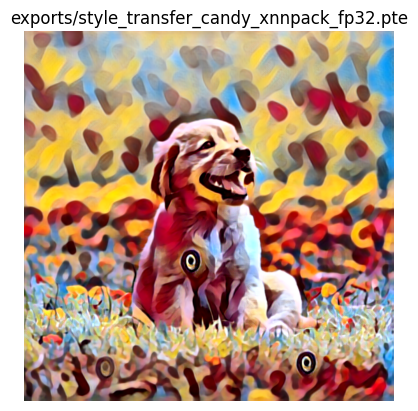

[program.cpp:154] InternalConsistency verification requested but not available


MOSAIC
Model size: 6.50 MB
Run successfully via Executorch in 1.60 seconds

Comparisson passed!



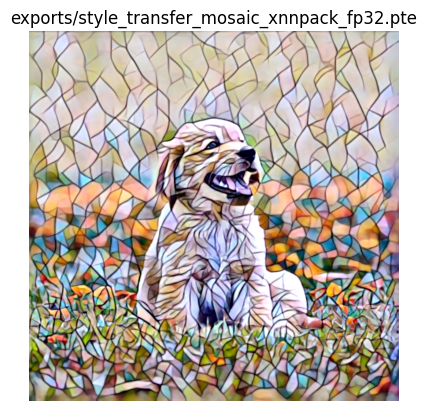

[program.cpp:154] InternalConsistency verification requested but not available


UDNIE
Model size: 6.50 MB
Run successfully via Executorch in 1.32 seconds

Comparisson passed!



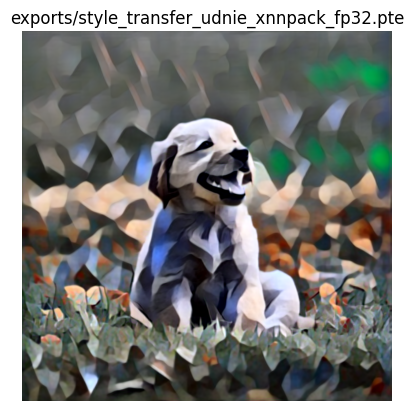

[program.cpp:154] InternalConsistency verification requested but not available


RAIN_PRINCESS
Model size: 6.50 MB
Run successfully via Executorch in 1.47 seconds

Comparisson passed!



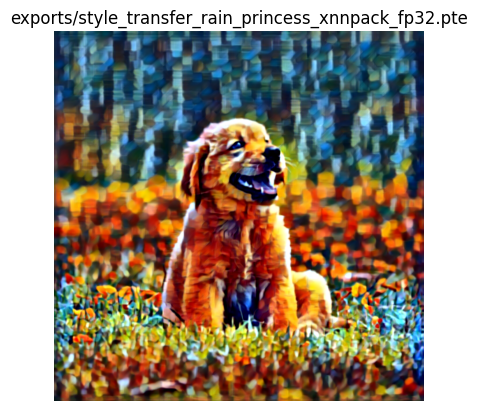

In [4]:
print("Verifying models...")

for model_name, wts_path in STYLES_MODELS.items():
    print(model_name.upper())
    path = MODEL_PATH[model_name]

    # --- Executorch inference ---
    img = decode_image("assets/dog.png").unsqueeze(0)
    img = F.resize(img, RESIZE_SIZE)
    img = F.convert_image_dtype(img, torch.float)

    t = time.perf_counter()
    runtime = Runtime.get()
    program = runtime.load_program(path)
    output, *_ = program.load_method("forward").execute([img])  # type: ignore
    t = time.perf_counter() - t

    print(
        f"Model size: {os.path.getsize(path) / 1024 / 1024:.2f} MB\n"
        f"Run successfully via Executorch in {t:.2f} seconds\n"
    )

    # --- PyTorch eager inference ---
    img = decode_image("assets/dog.png").unsqueeze(0)
    img = F.resize(img, RESIZE_SIZE)
    img = F.convert_image_dtype(img, torch.float)

    ref_model = load_style_transfer_model(wts_path)
    ref_output = ref_model(img)

    torch.testing.assert_close(output, ref_output, rtol=1e-2, atol=1e-3)
    print("Comparisson passed!\n")

    plt.imshow(output[0].permute(1, 2, 0).numpy())
    plt.title(path)
    plt.axis("off")
    plt.show()